# Stage 5 — Testing the Model

Questions:
- How well does the model rank customers it has never seen?
- What threshold should we use?
- What drives the scores?

**Rule:** pick the threshold using training data only, then test once. No changes after seeing the results.

The data is a snapshot, so this isn't a forecast of next month. Coefficients show links, not causes.

## Setup

Uses the same split and model as `03_modeling.ipynb`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, average_precision_score,
                             brier_score_loss, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import cross_val_predict

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from features import ID_COLUMN, load_modelling_data, split
from modeling import CV
from train_model import build_model

data = load_modelling_data()
X_train, X_test, y_train, y_test = split(data)

7,032 customers for modelling (11 with tenure = 0 excluded)
train 5,274 rows, churn 0.266
test  1,758 rows, churn 0.266   (untouched until Stage 5)


In [2]:
import matplotlib.pyplot as plt

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Same style as the Stage 3 charts.
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "grid.color": "#e5e5e2", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

## Pick a threshold (training data only)

Each training customer gets a score from a model that didn't see them. We pick the threshold with the best F1. It's a starting point; the business may value catching churners and avoiding wasted contacts differently.

In [3]:
oof_probabilities = cross_val_predict(
    build_model(), X_train, y_train, cv=CV, method="predict_proba"
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_probabilities)
oof_f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
best_index = np.flatnonzero(oof_f1 == oof_f1.max())[-1]
selected_threshold = float(thresholds[best_index])

print(f"OOF-selected threshold: {selected_threshold:.4f}")
print(f"OOF precision: {precision[best_index]:.3f}")
print(f"OOF recall:    {recall[best_index]:.3f}")
print(f"OOF F1:        {oof_f1[best_index]:.3f}")

OOF-selected threshold: 0.3187
OOF precision: 0.556
OOF recall:    0.740
OOF F1:        0.635


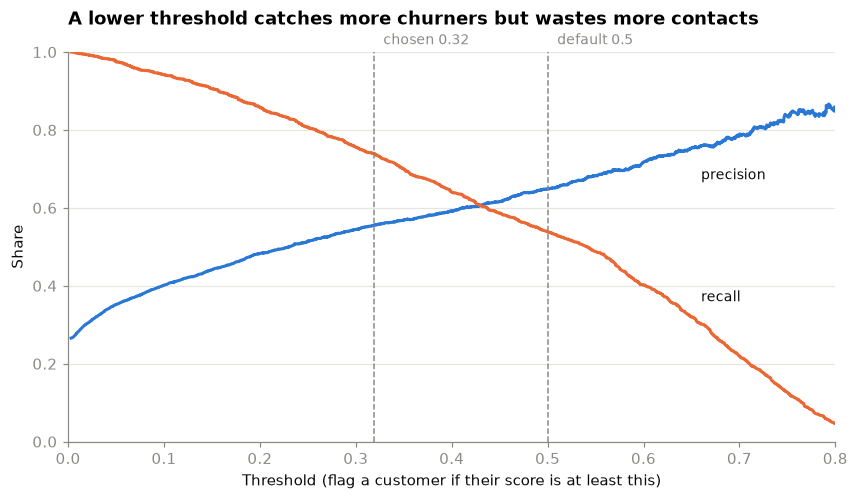

In [4]:
# Precision and recall at every threshold, on the training out-of-fold scores
# (the same data the threshold was picked from).
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(thresholds, precision[:-1], color=BLUE, linewidth=2)
ax.plot(thresholds, recall[:-1], color=ORANGE, linewidth=2)
ax.text(0.66, precision[:-1][np.searchsorted(thresholds, 0.65)] - 0.08, "precision",
        color=INK, fontsize=9)
ax.text(0.66, recall[:-1][np.searchsorted(thresholds, 0.65)] + 0.04, "recall",
        color=INK, fontsize=9)

for value, label in [(0.5, "default 0.5"), (selected_threshold, f"chosen {selected_threshold:.2f}")]:
    ax.axvline(value, color=MUTED, linewidth=1, linestyle="--")
    ax.text(value + 0.01, 1.02, label, color=MUTED, fontsize=9)

ax.set_title("A lower threshold catches more churners but wastes more contacts", pad=18)
ax.set_xlabel("Threshold (flag a customer if their score is at least this)")
ax.set_ylabel("Share")
ax.set_xlim(0, 0.8); ax.set_ylim(0, 1.0)
ax.grid(axis="y"); ax.set_axisbelow(True)
save(fig, "07_threshold_tradeoff")
plt.show()

## Test once

0.5 is shown for comparison. Don't change the threshold based on these results.

In [5]:
model = build_model().fit(X_train, y_train)
test_probabilities = model.predict_proba(X_test)[:, 1]
test_actual = y_test.to_numpy()

def operating_metrics(actual, predicted):
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {
        "customers_flagged": int(predicted.sum()),
        "share_flagged": predicted.mean(),
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "f1": f1_score(actual, predicted, zero_division=0),
        "accuracy": accuracy_score(actual, predicted),
        "specificity": tn / (tn + fp),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "false_negatives": int(fn),
    }

test_operating_points = pd.DataFrame({
    "threshold 0.50": operating_metrics(test_actual, (test_probabilities >= 0.5).astype(int)),
    "OOF-selected threshold": operating_metrics(
        test_actual, (test_probabilities >= selected_threshold).astype(int)),
}).T
test_operating_points.round(3)

,customers_flagged,share_flagged,precision,recall,f1,accuracy,specificity,true_positives,false_positives,false_negatives
threshold 0.50,408.0,0.232,0.654,0.572,0.610,0.806,0.891,267.0,141.0,200.0
OOF-selected threshold,639.0,0.363,0.543,0.743,0.627,0.766,0.774,347.0,292.0,120.0


In [6]:
base_rate = float(y_train.mean())
test_quality = pd.Series({
    "ROC-AUC": roc_auc_score(test_actual, test_probabilities),
    "PR-AUC (average precision)": average_precision_score(test_actual, test_probabilities),
    "Brier score": brier_score_loss(test_actual, test_probabilities),
    "Base-rate Brier baseline": brier_score_loss(
        test_actual, np.full(len(test_actual), base_rate)),
}, name="held-out test")
test_quality.round(4)

ROC-AUC                       0.8386
PR-AUC (average precision)    0.6231
Brier score                   0.1386
Base-rate Brier baseline      0.1951
Name: held-out test, dtype: float64

- **ROC-AUC / PR-AUC:** how well the model ranks customers.
- **Brier score:** how accurate the probabilities are (lower is better). Compare it with always guessing the average.

### How sure are we about these numbers?

The test set is one sample of 1,758 customers. To see how much the scores could move with a different sample, we resample the test set 2,000 times (bootstrapping) and recompute each score.

In [7]:
rng = np.random.default_rng(42)
boot = {"ROC-AUC": [], "PR-AUC (average precision)": []}
for _ in range(2000):
    idx = rng.integers(0, len(test_actual), len(test_actual))
    if test_actual[idx].min() == test_actual[idx].max():
        continue  # a resample with only one class has no AUC
    boot["ROC-AUC"].append(roc_auc_score(test_actual[idx], test_probabilities[idx]))
    boot["PR-AUC (average precision)"].append(
        average_precision_score(test_actual[idx], test_probabilities[idx]))

intervals = pd.DataFrame({
    "test score": test_quality[list(boot)],
    "low (2.5%)": {k: np.percentile(v, 2.5) for k, v in boot.items()},
    "high (97.5%)": {k: np.percentile(v, 97.5) for k, v in boot.items()},
})
intervals.round(3)

,test score,low (2.5%),high (97.5%)
ROC-AUC,0.839,0.818,0.857
PR-AUC (average precision),0.623,0.573,0.671


With a different sample of customers, ROC-AUC would likely land between **0.82 and 0.86**. The cross-validation score (0.844) sits inside that range, which confirms there's no overfitting.

## If we can only contact some customers

Rank by score and check the top 10%, 20% and 30%. These are examples, not targets.

In [8]:
def capacity_metrics(actual, probabilities, share):
    count = int(np.ceil(len(actual) * share))
    selected = np.argsort(-probabilities, kind="stable")[:count]
    churners_found = int(actual[selected].sum())
    return {
        "customers_contacted": count,
        "precision": churners_found / count,
        "recall": churners_found / int(actual.sum()),
        "churners_captured": churners_found,
    }

capacity_results = pd.DataFrame({
    f"top {share:.0%}": capacity_metrics(test_actual, test_probabilities, share)
    for share in (0.10, 0.20, 0.30)
}).T
capacity_results.round(3)

,customers_contacted,precision,recall,churners_captured
top 10%,176.0,0.699,0.263,123.0
top 20%,352.0,0.662,0.499,233.0
top 30%,528.0,0.598,0.677,316.0


The same idea as a curve, for every possible contact size:

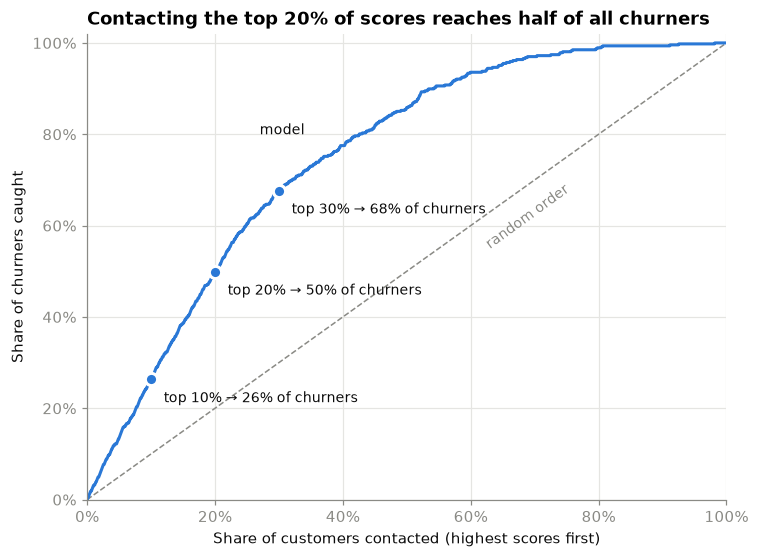

In [9]:
# Gains curve: contact customers from highest score down, and count churners caught.
order = np.argsort(-test_probabilities, kind="stable")
share_contacted = np.arange(1, len(order) + 1) / len(order)
share_caught = np.cumsum(test_actual[order]) / test_actual.sum()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
ax.text(0.62, 0.55, "random order", color=MUTED, fontsize=9, rotation=36)
ax.plot(np.r_[0, share_contacted], np.r_[0, share_caught], color=BLUE, linewidth=2)
ax.text(0.27, 0.80, "model", color=INK, fontsize=9)

for share in (0.10, 0.20, 0.30):
    caught = share_caught[int(np.ceil(len(order) * share)) - 1]
    ax.plot(share, caught, "o", color=BLUE, markersize=8,
            markeredgecolor="white", markeredgewidth=2)
    ax.text(share + 0.02, caught - 0.05, f"top {share:.0%} → {caught:.0%} of churners",
            color=INK, fontsize=9)

ax.set_title("Contacting the top 20% of scores reaches half of all churners")
ax.set_xlabel("Share of customers contacted (highest scores first)")
ax.set_ylabel("Share of churners caught")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.grid(); ax.set_axisbelow(True)
save(fig, "08_gains_curve")
plt.show()

## Are the probabilities accurate?

Compare predicted and actual churn in each score group. Small groups can be noisy.

In [10]:
calibration = pd.DataFrame({
    "probability": test_probabilities,
    "actual": test_actual,
})
calibration["decile"] = pd.qcut(calibration["probability"], 10, duplicates="drop")
calibration = calibration.groupby("decile", observed=True).agg(
    customers=("actual", "size"),
    mean_probability=("probability", "mean"),
    observed_churn_rate=("actual", "mean"),
)
calibration["gap_percentage_points"] = (
    100 * (calibration["observed_churn_rate"] - calibration["mean_probability"])
)
calibration.round(3)

,customers,mean_probability,observed_churn_rate,gap_percentage_points
decile,,,,
"(0.00286, 0.0139]",176,0.009,0.017,0.815
"(0.0139, 0.0316]",176,0.022,0.011,-1.031
"(0.0316, 0.0638]",176,0.046,0.051,0.535
"(0.0638, 0.125]",175,0.091,0.091,0.016
"(0.125, 0.188]",176,0.158,0.205,4.652
"(0.188, 0.284]",176,0.231,0.222,-0.987
"(0.284, 0.414]",175,0.343,0.263,-7.988
"(0.414, 0.538]",176,0.478,0.472,-0.640
"(0.538, 0.667]",176,0.609,0.625,1.617


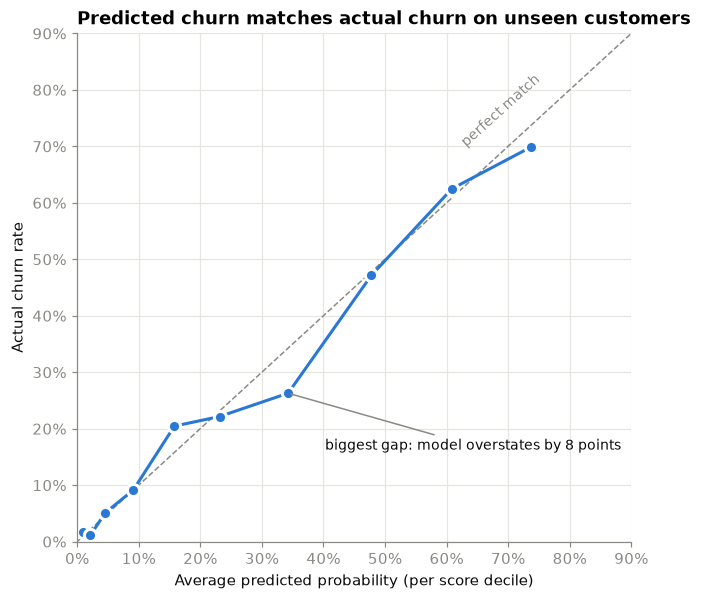

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 0.9], [0, 0.9], color=MUTED, linewidth=1, linestyle="--")
ax.text(0.62, 0.70, "perfect match", color=MUTED, fontsize=9, rotation=42)
ax.plot(calibration["mean_probability"], calibration["observed_churn_rate"], "o-",
        color=BLUE, linewidth=2, markersize=8, markeredgecolor="white", markeredgewidth=2)

worst = calibration["gap_percentage_points"].abs().idxmax()
row = calibration.loc[worst]
ax.annotate(f"biggest gap: model {'over' if row['gap_percentage_points'] < 0 else 'under'}states by {abs(row['gap_percentage_points']):.0f} points",
            (row["mean_probability"], row["observed_churn_rate"]),
            xytext=(row["mean_probability"] + 0.06, row["observed_churn_rate"] - 0.10),
            color=INK, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED))

ax.set_title("Predicted churn matches actual churn on unseen customers")
ax.set_xlabel("Average predicted probability (per score decile)")
ax.set_ylabel("Actual churn rate")
ax.set_xlim(0, 0.9); ax.set_ylim(0, 0.9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.grid(); ax.set_axisbelow(True)
save(fig, "09_calibration")
plt.show()

## What drives the score

Odds ratios above 1 raise the score; below 1 lower it. Each is compared to that variable's base category. These explain the model, they don't show causes.

In [12]:
coefficients = model.named_steps["model"].coef_[0]
feature_names = model.named_steps["prep"].get_feature_names_out()
effects = pd.DataFrame({"feature": feature_names, "log_odds": coefficients})
effects["odds_ratio"] = np.exp(effects["log_odds"])

print("Largest positive coefficients")
display(effects.nlargest(10, "log_odds").round(3))
print("Largest negative coefficients")
display(effects.nsmallest(10, "log_odds").round(3))

Largest positive coefficients


,feature,log_odds,odds_ratio
6,categorical__InternetService_Fiber optic,0.915,2.496
18,categorical__PaymentMethod_Electronic check,0.344,1.411
5,categorical__MultipleLines_Yes,0.340,1.404
16,categorical__PaperlessBilling_Yes,0.328,1.388
12,categorical__StreamingTV_Yes,0.315,1.370
13,categorical__StreamingMovies_Yes,0.273,1.314
1,categorical__SeniorCitizen_1,0.197,1.217
19,categorical__PaymentMethod_Mailed check,0.132,1.141
10,categorical__DeviceProtection_Yes,0.029,1.030
2,categorical__Partner_Yes,0.011,1.011


Largest negative coefficients


,feature,log_odds,odds_ratio
15,categorical__Contract_Two year,-1.307,0.271
7,categorical__InternetService_No,-0.866,0.421
20,numeric__tenure,-0.805,0.447
14,categorical__Contract_One year,-0.678,0.507
4,categorical__PhoneService_Yes,-0.509,0.601
8,categorical__OnlineSecurity_Yes,-0.409,0.664
11,categorical__TechSupport_Yes,-0.406,0.666
3,categorical__Dependents_Yes,-0.256,0.774
9,categorical__OnlineBackup_Yes,-0.170,0.844
0,categorical__gender_Male,-0.037,0.964


The same coefficients as a chart. Orange raises the score, blue lowers it.

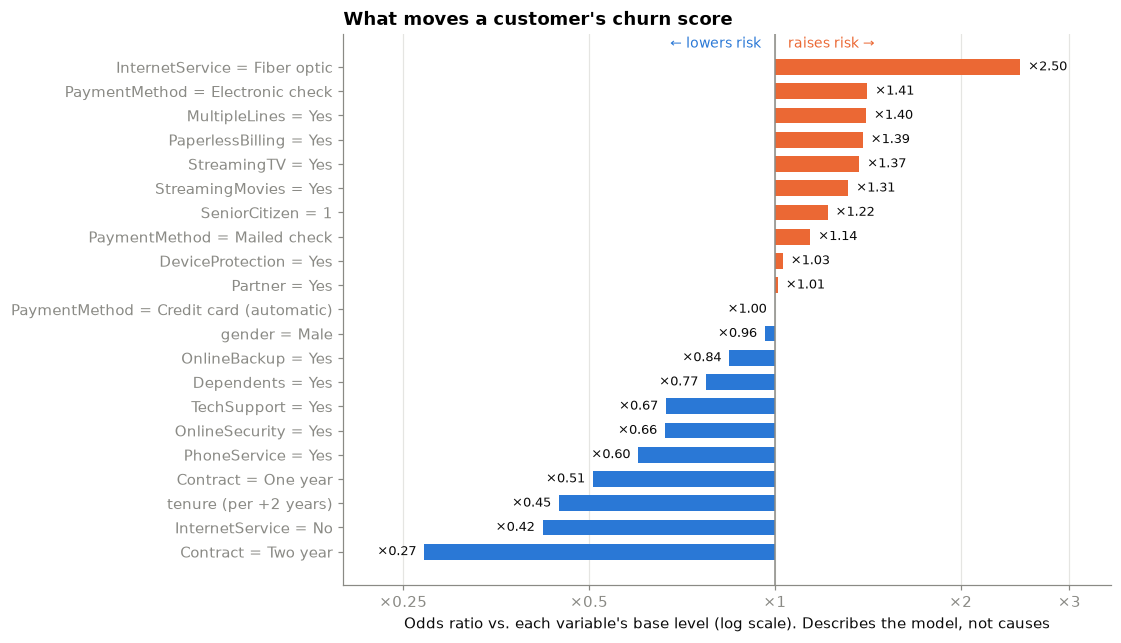

In [13]:
# tenure is standardised, so its odds ratio is per one standard deviation.
tenure_sd_years = model.named_steps["prep"].named_transformers_["numeric"].scale_[0] / 12

def readable(feature):
    name = feature.split("__", 1)[1]
    if name == "tenure":
        return f"tenure (per +{tenure_sd_years:.0f} years)"
    column, level = name.rsplit("_", 1)
    return f"{column} = {level}"

drivers = effects.assign(label=effects["feature"].map(readable)).sort_values("log_odds")

fig, ax = plt.subplots(figsize=(9, 6.5))
colors = [ORANGE if value > 0 else BLUE for value in drivers["log_odds"]]
bars = ax.barh(drivers["label"], drivers["log_odds"], color=colors, height=0.65)
for bar, ratio in zip(bars, drivers["odds_ratio"]):
    width = bar.get_width()
    ax.text(width + (0.03 if width >= 0 else -0.03), bar.get_y() + bar.get_height() / 2,
            f"×{ratio:.2f}", va="center", ha="left" if width >= 0 else "right",
            color=INK, fontsize=8.5)

ax.axvline(0, color=MUTED, linewidth=1)
ticks = [0.25, 0.5, 1, 2, 3]
ax.set_xticks(np.log(ticks))
ax.set_xticklabels([f"×{t:g}" for t in ticks])
ax.set_xlim(np.log(0.2), np.log(3.5))
ax.text(np.log(1.05), len(drivers) - 0.2, "raises risk →", color=ORANGE, fontsize=9)
ax.text(np.log(0.95), len(drivers) - 0.2, "← lowers risk", color=BLUE, fontsize=9, ha="right")

ax.set_title("What moves a customer's churn score")
ax.set_xlabel("Odds ratio vs. each variable's base level (log scale). Describes the model, not causes")
ax.grid(axis="x"); ax.set_axisbelow(True)
save(fig, "10_score_drivers")
plt.show()

## Who does the model miss?

At the chosen threshold, some churners are not flagged. Compare them with the churners the model did catch, and with customers who stayed.

In [14]:
test_rows = data.loc[X_test.index].assign(
    score=test_probabilities,
    flagged=test_probabilities >= selected_threshold,
)
test_rows["group"] = np.where(
    test_rows["y"].eq(0), "stayed",
    np.where(test_rows["flagged"], "churned, caught", "churned, missed"),
)

def profile(rows):
    return pd.Series({
        "customers": len(rows),
        "median tenure (months)": rows["tenure"].median(),
        "month-to-month %": 100 * rows["Contract"].eq("Month-to-month").mean(),
        "one/two-year contract %": 100 * rows["Contract"].ne("Month-to-month").mean(),
        "fiber optic %": 100 * rows["InternetService"].eq("Fiber optic").mean(),
        "no internet %": 100 * rows["InternetService"].eq("No").mean(),
        "electronic check %": 100 * rows["PaymentMethod"].eq("Electronic check").mean(),
        "median monthly charge $": rows["MonthlyCharges"].median(),
        "average score": rows["score"].mean(),
    })

missed_profile = test_rows.groupby("group").apply(profile).T[
    ["churned, caught", "churned, missed", "stayed"]]
missed_profile.round(1)

group,"churned, caught","churned, missed",stayed
customers,347.0,120.0,1291.0
median tenure (months),7.0,24.0,39.0
month-to-month %,98.6,60.0,43.7
one/two-year contract %,1.4,40.0,56.3
fiber optic %,82.7,30.0,34.8
no internet %,0.0,25.8,27.2
electronic check %,66.6,27.5,24.3
median monthly charge $,80.0,55.9,64.5
average score,0.6,0.2,0.2


In [15]:
# Where do the missed churners sit? Their share of each contract type's churners.
churners = test_rows[test_rows["y"].eq(1)]
missed_by_contract = churners.groupby("Contract").agg(
    churners=("y", "size"),
    missed=("flagged", lambda f: int((~f).sum())),
)
missed_by_contract["missed %"] = 100 * missed_by_contract["missed"] / missed_by_contract["churners"]
missed_by_contract.round(1)

,churners,missed,missed %
Contract,,,
Month-to-month,414,72,17.4
One year,43,38,88.4
Two year,10,10,100.0


**The missed churners look like customers who stay.** Compared with the churners the model caught:

- Longer tenure: median **24 months** vs 7
- **40%** are on one- or two-year contracts (vs 1%)
- Less fiber (30% vs 83%) and less electronic check (28% vs 67%)
- **26%** have no internet at all (vs 0%)

The contract table makes it clear: the model catches most month-to-month churners (misses 17%), but misses **48 of the 53** churners on one- or two-year contracts.

This is a limit of the data, not a bug. Nothing in these columns separates a contract customer who will leave from one who will stay. Catching them would need other signals, like complaints, support calls or a contract end date.

## Save test scores

Customer IDs are kept for checking, not used by the model. This is the test set only, so it's not a contact list.

In [16]:
test_predictions = pd.DataFrame({
    ID_COLUMN: data.loc[X_test.index, ID_COLUMN].to_numpy(),
    "churn_actual": test_actual,
    "churn_probability": test_probabilities,
    "flagged_at_oof_f1_threshold": (test_probabilities >= selected_threshold).astype(int),
    "oof_f1_threshold": selected_threshold,
})
prediction_path = ROOT / "data" / "processed" / "churn_test_predictions.csv"
prediction_path.parent.mkdir(parents=True, exist_ok=True)
test_predictions.sort_values("churn_probability", ascending=False).to_csv(
    prediction_path, index=False)
print(f"Saved {len(test_predictions):,} held-out scores to {prediction_path.relative_to(ROOT)}")

Saved 1,758 held-out scores to data/processed/churn_test_predictions.csv


## Results

- **ROC-AUC 0.839** on the test set (likely range 0.82–0.86) vs 0.844 in cross-validation. No overfitting.
- **Threshold 0.32** catches 74% of churners vs 57% at 0.5, but contacts more customers who would have stayed.
- **Top 20%** of scores holds half of all churners.
- **Probabilities match** actual churn within 5 points in 9 of 10 groups.
- **Missed churners look like stayers:** longer tenure and often on contracts. The model misses 48 of 53 contract churners.
- **Streaming and multiple lines** raise the score because they cost extra. They stand in for price, not churn causes.

## Next

- Don't change the model or threshold based on these results.
- The final threshold depends on how many customers the team can contact and the cost of a missed churner vs a wasted contact.
- Stage 6 combines scores with customer value to build the priority list.
- The data can't show future churn or whether offers work.